# Variational Autoencoders (VAE) on Fashion MNIST

**Goal:**
- Load the Fashion MNIST dataset and pad images to 32×32.
- Build a **VAE** that learns a latent distribution N(μ, σ²) instead of a fixed vector.
- Train with a combined loss: Reconstruction Loss + β × KL Divergence.
- Visualize the latent space and generate new images by sampling from N(0, I).

## 1: Data Preparation and Visualization

Identical to the first practical exercise.

**Key points to recall:**
- We pad 28×28 → 32×32 so that three stride-2 convolutions produce a clean spatial dimension (4×4), avoiding size mismatch issues in the decoder.
- `ToTensor()` normalizes pixels to [0, 1], which is required by the Sigmoid output and BCE loss.
- Shuffling the training set prevents the model from learning order artifacts.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from tqdm import tqdm

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [2]:
# Preprocessing
transform = transforms.Compose([
    transforms.Pad(2),      # Pad 28x28 → 32x32
    transforms.ToTensor(),  # Convert to tensor, normalize to [0, 1]
])

batch_size = 128

# Load data
train_dataset = datasets.FashionMNIST(root="./data", train=True,  transform=transform, download=True)
train_loader  = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset   = datasets.FashionMNIST(root="./data", train=False, transform=transform, download=True)
val_loader    = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False)

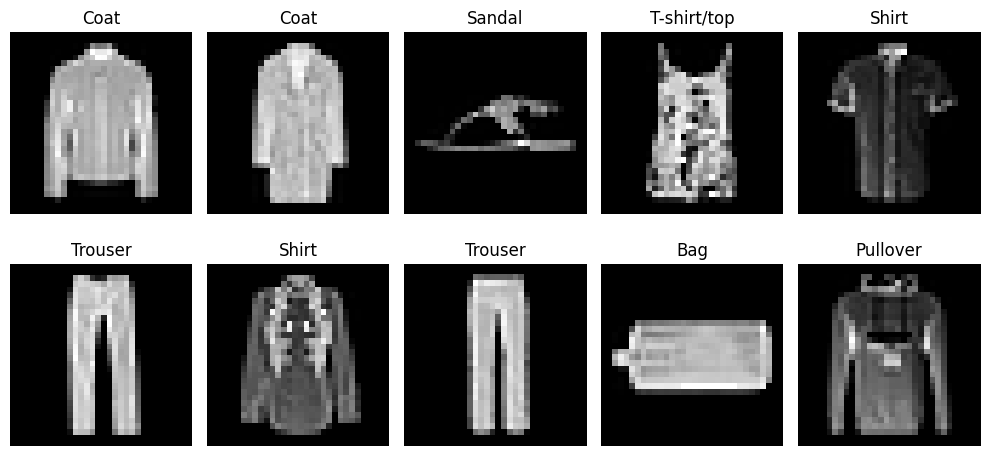

In [3]:
class_labels = {
    0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat',
    5: 'Sandal',      6: 'Shirt',   7: 'Sneaker',  8: 'Bag',   9: 'Ankle boot'
}

def plot_sample_images(loader):
    data_iter = iter(loader)
    images, labels = next(data_iter)
    images = images.numpy()
    plt.figure(figsize=(10, 5))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.title(class_labels[labels[i].item()])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

plot_sample_images(train_loader)

## 2: Define the VAE Model

### Key difference from a standard Autoencoder

Instead of learning a fixed latent vector **z**, the VAE learns a **distribution** N(μ, σ²):
- The encoder outputs **μ** (mean) and **log(σ²)** (log-variance).
- A latent sample is drawn via the **reparameterization trick**:

> z = μ + σ × ε,   ε ~ N(0, I)

**Why separate heads for μ and log(σ²)?**  
They represent different statistics of the distribution. Having two independent linear projections lets the model learn them separately without one constraining the other.

**Why does the reparameterization trick help?**  
Sampling is a non-differentiable operation. By writing z = μ + σ·ε (with ε fixed as random noise), the randomness is moved outside the computation graph, so gradients can flow back through μ and σ normally.

In [4]:
class VAE(nn.Module):
    def __init__(self, input_shape=(1, 32, 32), latent_dim=2):
        """
        Variational Autoencoder.
        Args:
            input_shape (tuple): Shape of the input image, default (1, 32, 32).
            latent_dim  (int)  : Dimension of the latent representation.
        """
        super(VAE, self).__init__()

        # ------------------
        # 1. Encoder
        # ------------------
        # Progressively reduces spatial dimensions using stride-2 convolutions.
        self.encoder = nn.Sequential(
            nn.Conv2d(1,  32,  kernel_size=3, stride=2, padding=1),  # → (32, 16, 16)
            nn.ReLU(),
            nn.Conv2d(32, 64,  kernel_size=3, stride=2, padding=1),  # → (64,  8,  8)
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),  # → (128, 4,  4)
            nn.ReLU()
        )

        # Dynamically compute the flattened size after the encoder
        flattened_size, decode_shape = self.calculate_flattened_size(self.encoder, input_shape)

        # ------------------------------------------------
        # 2. Fully Connected Layers for Latent Space
        # ------------------------------------------------
        # Two separate heads:
        #   fc_mu    → predicts the mean of the latent distribution
        #   fc_logvar → predicts the log-variance of the latent distribution
        self.fc_mu = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(flattened_size, latent_dim)
        )
        self.fc_logvar = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(flattened_size, latent_dim)  # same dimension as mu
        )

        # ------------------
        # 3. Decoder
        # ------------------
        # Inverts the encoder with ConvTranspose2d (deconvolutions).
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, flattened_size),
            nn.Unflatten(decode_shape[0], decode_shape[1:]),          # reshape to (128, 4, 4)
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),  # → (64, 8, 8)
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),   # → (32, 16, 16)
            nn.ReLU(),
            nn.ConvTranspose2d(32,  1, kernel_size=3, stride=2, padding=1, output_padding=1),   # → (1, 32, 32)
            nn.Sigmoid()  # pixel values in [0, 1]
        )

    # ------------------------------------------------------------------
    def reparameterize(self, mu, logvar):
        """
        Reparameterization trick: z = mu + sigma * eps, eps ~ N(0, I)
        Args:
            mu     (Tensor): Mean of the latent distribution.
            logvar (Tensor): Log-variance of the latent distribution.
        Returns:
            z (Tensor): Sampled latent variable.
        """
        std = torch.exp(0.5 * logvar)   # σ = exp(0.5 * log σ²)
        eps = torch.randn_like(std)     # ε ~ N(0, I)
        return mu + std * eps

    # ------------------------------------------------------------------
    def calculate_flattened_size(self, model, input_shape):
        """Helper: compute flattened size and shape after the encoder."""
        with torch.no_grad():
            dummy_input = torch.zeros(1, *input_shape)
            output = model(dummy_input)
            return output.numel(), output.shape

    # ------------------------------------------------------------------
    def forward(self, x):
        """
        Forward pass:
          1) Encode → μ, log(σ²)
          2) Sample z via reparameterization
          3) Decode z → reconstructed image
        Returns: recon_x, mu, logvar, z
        """
        x_encoded = self.encoder(x)
        mu     = self.fc_mu(x_encoded)
        logvar = self.fc_logvar(x_encoded)
        z      = self.reparameterize(mu, logvar)
        recon_x = self.decoder(z)
        return recon_x, mu, logvar, z

In [5]:
# Test dimension consistency
x_sample   = torch.randn(1, 1, 32, 32)
model_test = VAE()
image_test, mu, logvar, z = model_test(x_sample)
assert image_test.shape == x_sample.shape, "Output dimensions do not match input dimensions!"
print(f"Input shape:   {x_sample.shape}")
print(f"Output shape:  {image_test.shape}")
print(f"mu shape:      {mu.shape}")
print(f"logvar shape:  {logvar.shape}")
print(f"z shape:       {z.shape}")
print("Dimension test passed!")

Input shape:   torch.Size([1, 1, 32, 32])
Output shape:  torch.Size([1, 1, 32, 32])
mu shape:      torch.Size([1, 2])
logvar shape:  torch.Size([1, 2])
z shape:       torch.Size([1, 2])
Dimension test passed!


## 3: VAE Loss Function and Training

### VAE Loss
The total loss combines:
1. **Reconstruction Loss** — Binary Cross-Entropy (BCE) between input and reconstruction.
2. **KL Divergence** — Regularizes the latent space toward N(0, I):

> KL(q(z|x) ‖ p(z)) = -½ Σ (1 + log σ² - μ² - σ²)

### β-VAE
Adding a weight β to the KL term controls the trade-off:
- **β = 1**: standard VAE.
- **β > 1**: stronger regularization → more disentangled latent space, but potentially blurrier reconstructions.
- **β < 1**: better reconstructions, less structure in latent space.

**How does a larger β change the trade-off?**  
A large β pushes the posterior q(z|x) closer to N(0,I), forcing the model to compress information more aggressively. This often produces more interpretable latent dimensions (disentanglement) but sacrifices reconstruction sharpness.

In [6]:
def vae_loss(recon_x, x, mu, logvar, beta=1):
    """
    VAE loss = Reconstruction loss + β * KL divergence.

    Args:
        recon_x (Tensor): Reconstructed images.
        x       (Tensor): Original input images.
        mu      (Tensor): Mean of the latent distribution.
        logvar  (Tensor): Log-variance of the latent distribution.
        beta    (float) : Weight for the KL term (β-VAE).
    Returns:
        total_loss (Tensor): Reconstruction loss + β * KL divergence.
    """
    # 1) Reconstruction Loss (BCE, sum over all pixels)
    recon_loss = F.binary_cross_entropy(recon_x, x, reduction='sum')

    # 2) KL Divergence: -0.5 * Σ (1 + logvar - mu² - exp(logvar))
    kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    return recon_loss + beta * kl_div

In [7]:
def plot_training_loss(train_losses, val_losses):
    """Plot training and validation loss curves."""
    plt.figure(figsize=(8, 5))
    plt.plot(train_losses, label="Training Loss",   marker="o")
    plt.plot(val_losses,   label="Validation Loss", marker="s")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid()
    plt.show()


def evaluate_model(model, loader, beta=1):
    """
    Evaluate the VAE on a validation dataset.
    Returns avg_loss (float) and a placeholder for extra metrics.
    """
    model.eval()
    total_loss = 0
    ce_loss_placeholder = 0

    with torch.no_grad():
        for x, _ in tqdm(loader, desc="Evaluating"):
            x = x.to(device)
            recon_x, mu, logvar, _ = model(x)
            loss = vae_loss(recon_x, x, mu, logvar, beta=beta)
            total_loss += loss.item()

    avg_loss = total_loss / len(loader.dataset)
    return avg_loss, ce_loss_placeholder


def train_model(model, train_loader, val_loader, epochs, beta=1):
    """
    Train the VAE.
    Args:
        model        (nn.Module)  : VAE instance.
        train_loader (DataLoader) : Training data.
        val_loader   (DataLoader) : Validation data.
        epochs       (int)        : Number of epochs.
        beta         (float)      : KL weight for β-VAE.
    """
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    train_losses, val_losses = [], []

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        tqdm_loader = tqdm(train_loader, desc=f"Training Epoch {epoch+1}/{epochs}")
        for x, _ in tqdm_loader:
            optimizer.zero_grad()            # 1) zero gradients
            x = x.to(device)                 # 2) move to device
            recon_x, mu, logvar, _ = model(x)  # 3) forward pass
            loss = vae_loss(recon_x, x, mu, logvar, beta=beta)  # 4) loss
            loss.backward()                  # 5) backpropagation
            optimizer.step()                 # 6) update weights

            total_loss += loss.item()
            tqdm_loader.set_postfix(loss=loss.item())

        avg_train_loss = total_loss / len(train_loader.dataset)
        avg_val_loss, _ = evaluate_model(model, val_loader, beta=beta)

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)

        print(f"Epoch [{epoch+1}/{epochs}]  "
              f"Train Loss: {avg_train_loss:.4f}  "
              f"Val Loss: {avg_val_loss:.4f}")

    plot_training_loss(train_losses, val_losses)

Training VAE...


Evaluating: 100%|██████████| 79/79 [00:03<00:00, 19.82it/s]


Epoch [1/20]  Train Loss: 424.2161  Val Loss: 324.0361


Evaluating: 100%|██████████| 79/79 [00:03<00:00, 20.23it/s]


Epoch [2/20]  Train Loss: 306.0715  Val Loss: 298.1985


...

Epoch [18/20]  Train Loss: 272.2869  Val Loss: 273.9787


Evaluating: 100%|██████████| 79/79 [00:03<00:00, 20.50it/s]


Epoch [19/20]  Train Loss: 271.9260  Val Loss: 273.2488


Evaluating: 100%|██████████| 79/79 [00:04<00:00, 19.41it/s]


Epoch [20/20]  Train Loss: 271.5556  Val Loss: 272.9660


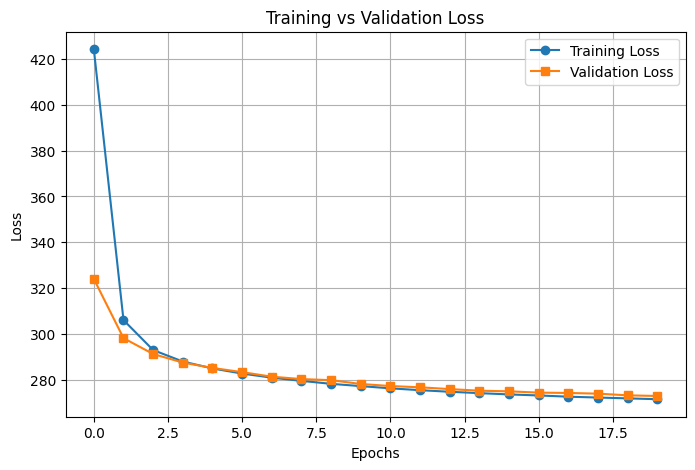

In [8]:
# Instantiate and train the VAE
vae = VAE().to(device)
print("Training VAE...")
train_model(vae, train_loader, val_loader, epochs=20, beta=1.5)

In [9]:
# (Optional) Load a pre-trained model instead of training from scratch
# You must have run at least one epoch before loading.

# path = "VAmodel_state_dict.pth"   # path to saved weights
# vae = VAE().to(device)
# vae.load_state_dict(torch.load(path, map_location=device))
# vae.eval()
# print("Pre-trained model loaded.")

## 4: Reconstruct Images

Take a batch of original images, pass them through the VAE, and compare side-by-side.

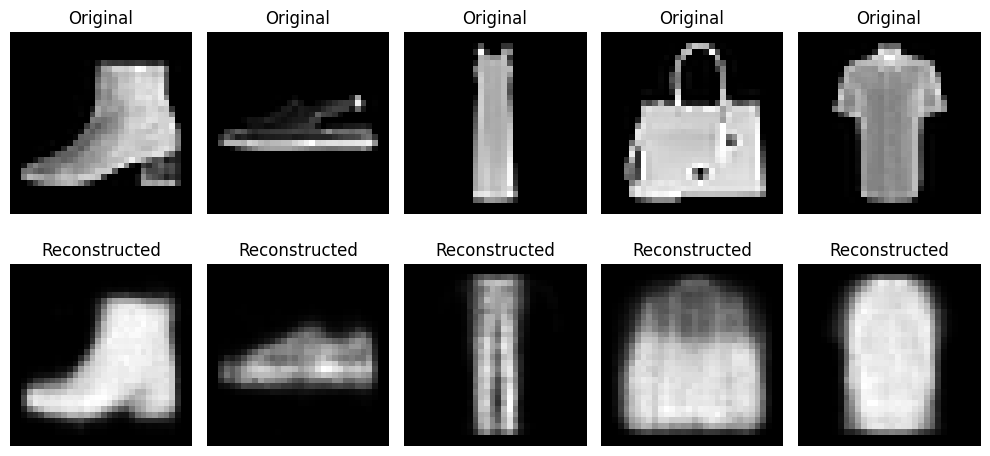

In [10]:
def plot_reconstructions(model, loader_or_z, ex=True, num_samples=5):
    """
    Plot original and reconstructed images.
    Args:
        model       : Trained VAE.
        loader_or_z : DataLoader (real images) OR latent tensor (for generation).
        ex          : True → use DataLoader; False → use provided latent vectors.
        num_samples : Number of images to display.
    """
    model.eval()
    model = model.to("cpu")

    with torch.no_grad():
        if ex:
            for x, _ in loader_or_z:
                recon_x, _, _, _ = model(x)
                break
        else:
            x = None
            recon_x = model.decoder(loader_or_z)

    if x is not None:
        x = x.cpu().numpy()
    recon_x = recon_x.cpu().numpy()

    plt.figure(figsize=(10, 5))
    for i in range(num_samples):
        if x is not None:
            plt.subplot(2, num_samples, i + 1)
            plt.imshow(x[i].squeeze(), cmap="gray")
            plt.title("Original")
            plt.axis("off")

        plt.subplot(2, num_samples, i + 1 + num_samples)
        plt.imshow(recon_x[i].squeeze(), cmap="gray")
        plt.title("Reconstructed")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


plot_reconstructions(vae, train_loader, ex=True)

## 5: Visualize the Latent Space

Extract the **μ** (mean) from the encoder for each training image and plot the 2D embeddings, color-coded by clothing category.

Thanks to the KL regularization, the VAE latent space should be **more structured and centered around 0** compared to the plain AE.

In [11]:
embeddings = []
labels     = []

vae = vae.to(device)

with torch.no_grad():
    for x, y in train_loader:
        x = x.to(device)
        _, mu, _, _ = vae(x)          # we use mu as the embedding
        latent = mu
        embeddings.append(latent.cpu().numpy())
        labels.append(y.numpy())

embeddings = np.concatenate(embeddings, axis=0)
labels     = np.concatenate(labels,     axis=0)

unique_labels = np.unique(labels)
vae = vae.to("cpu")

print(f"Embeddings shape: {embeddings.shape}")

Embeddings shape: (60000, 2)


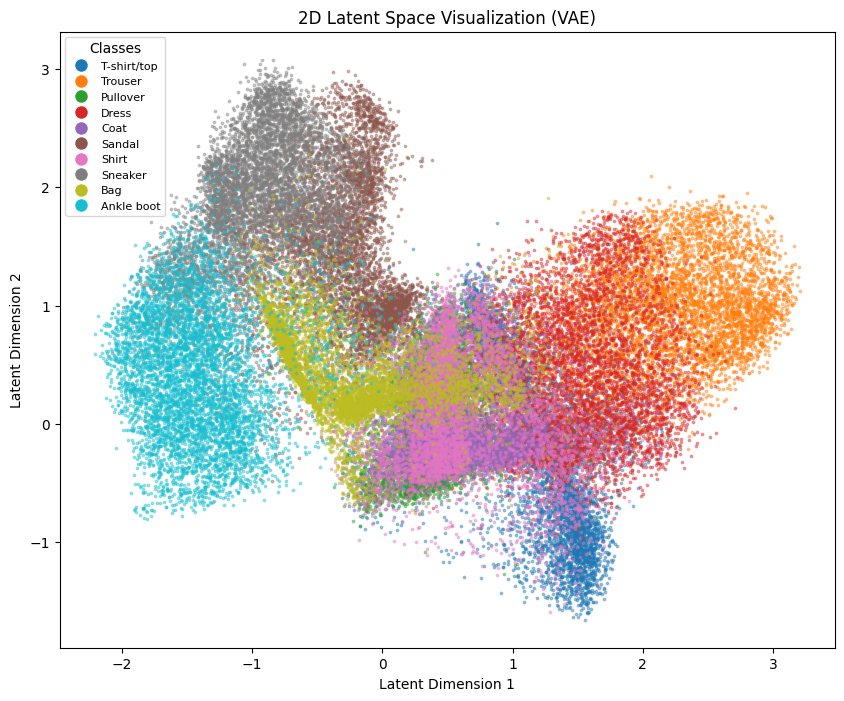

In [12]:
# Plot 2D latent space
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

plt.figure(figsize=(10, 8))
legend_handles = []

for i, label in enumerate(unique_labels):
    indices = np.where(labels == label)[0]
    plt.scatter(
        embeddings[indices, 0], embeddings[indices, 1],
        c=[colors[i]], alpha=0.4, s=3, label=class_labels[label]
    )
    legend_handles.append(
        Line2D([0], [0], marker='o', color='w', label=f'{class_labels[label]}',
               markersize=10, markerfacecolor=colors[i])
    )

plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.title('2D Latent Space Visualization (VAE)')
plt.legend(handles=legend_handles, title='Classes', loc='upper left', fontsize=8)
plt.show()

## 6: Generate New Images

Because the VAE regularizes the latent space toward **N(0, I)**, we can sample random points directly from the standard normal distribution and decode them into plausible clothing images — something that doesn't work as reliably with a plain AE.

Sampled latent vectors:
 tensor([[-0.4491, -1.0672],
        [-0.8678,  0.4660],
        [-0.4357,  0.6739],
        [ 0.5763,  0.7367],
        [-2.3308, -0.2845]])


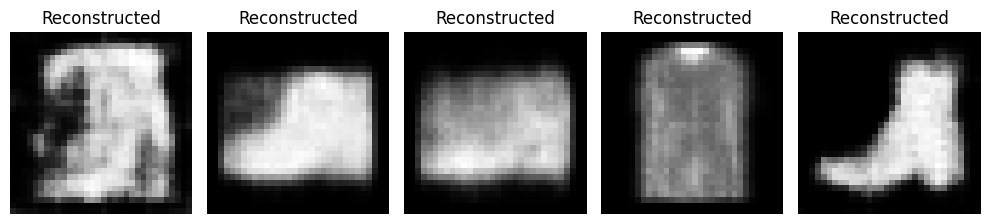

In [13]:
# Sample from N(0, I) and generate images
z_sample = torch.tensor(
    np.random.normal(size=(5, 2)),
    dtype=torch.float32
)
print("Sampled latent vectors:\n", z_sample)
plot_reconstructions(vae, z_sample, ex=False)

In [14]:
# Save the trained VAE
torch.save(vae.state_dict(), "VAE_model_state_dict.pth")
print("VAE model saved to VAE_model_state_dict.pth")

VAE model saved to VAE_model_state_dict.pth
